http://127.0.0.1:8888/lab/tree/thesis/chapter_colab/scripts/section-ctd_dalton/section-ctd/0danilo_sections.py

In [2]:
import warnings
warnings.filterwarnings('ignore')

from rtree import index
import numpy as np
import pandas as pd
import glob
import os.path as osp
import xarray as xr
import logging
import gsw
import matplotlib.pyplot as plt
import numpy as np
import pickle
from matplotlib import ticker

import sys
sys.path.insert(0, 'section-ctd_dalton/section-ctd')
from utils import utils as ut
from utils import maps

# Functions

In [3]:
def find_nearest(lon,lat,ilon,ilat,k=1):
    """ Find nearest coordinates to a given coordinate, given by ilon and ilat,
    in a grid defined by lon and lat arguments.

    Parameters
    ----------
    lon     : np.ndarray
        2D array with gridded longitudes.
    lat     : np.ndarray
        2D array with gridded latitudes.
    ilon    : float
        Specific longitude of the coordinate of interest.
    ilat    : float
        Specific latitude of the coordinate of interest.

    Returns
    -------
    iss,jss : list
        Indexes of the i,j pair of the nearest point found.
    """
    from scipy import spatial

    # generating coords pairs of longitude and latitude
    lo,la = lon.ravel(), lat.ravel()
    coords = []
    for o,a in zip(lo,la):
         coords.append((o,a))

    # define tuple with the interest coordinates
    x = [(ilon,ilat)]

    # using cKDTree to find the nearest points
    dists,indexes = spatial.cKDTree(coords).query(x, k=k)

    # indexes are given considering the flatten 2D arrays for lon and lat. We must
    # now transform this single index in a i,j form, so we can use in the 2D arrays
    # of the model
    points = []

    for index in indexes:
        points.append(coords[index])

    # converting list to array
    points = np.asarray(points)

    # findind indexes from lat and lon
    ind = []

    for p in points:
        tmp = np.where(np.logical_and(lon == p[0], lat == p[1]))
        ind.append(tmp)

    ind = np.asarray(ind)

    # separating i and j in two lists
    iss=[]
    jss=[]

    for i,j in ind:
        iss.append(int(i))
        jss.append(int(j))

    return iss,jss

def prepare_reference_table(fpath, ctdpath=None, ctdformat=None, decimal='.'):
    """Reads the csv reference table with the metadata on each station at
    each section. The function also includes a column with  ctd 'paths'
    in the dataframe. The csv must contain a column 'station', with the
    ctd file name (WITHOUT extension)


    Args:
        fpath (str):
            reference table file name (.csv)

        ctdpath (str, optional):
            ctd directory path with nc files produced by cnv2nc
                If ctdformat is None, this argument is ignored
        ctdformat (str, optional):
            file extension of the ctd files.
                If None, the original table is returned
                If 'nc', the files outputtedby cnv2nc will be read.

    Returns (pandas dataframe):
        Dataframe with nformation of the csv table
        and correspoding ctd paths
    """    
    ctdf = ctdformat
    df = pd.read_csv(fpath, decimal=decimal)  # read table 
    
    if ctdformat is not None:
        ctdpaths = [osp.join(ctdpath, f'{i}.{ctdf}') for i in df['station']] 
        ctdpaths1 = []
        for i in ctdpaths:
            aux = glob.glob(i)
            ctdpaths1.append(aux) if len(aux)>0 else print(i)
        logging.info(f"include 'paths' as a dataframe column with  the paths of ctd files with {ctdformat} format")
        df['paths'] = ctdpaths

    return df

def read_section(df, section, reference_table=[]):
    """Creates a ctd Dataframe based on the section and
    df (reference metadata dataframe created with prepare_reference_table)

    Args:
        df (pandas dataframe):
            dataframe created by prepare_reference_table method
        section (str):
            A given section ID in df
        reference_table (list, optional):
            Strings contained in this list are referenced to column keys in 
            df. The respective values are added in respective columns in the
            dataframe output . Defaults to [].

    Returns (pandas dataframe):
        A dataframe with the information of a given section with
        information updated from df[reference_table]
    """    
    # -- section -- #
    groups = df.groupby('section')
    dfg = groups.get_group(section)

    # -- read using netcdf -- #
    # netcdf of a given ctd data MUST contain lon, lat, time as 
    # attributes
    dfaux1 = []
    id = {}
    for j,i in dfg.iterrows():
        id[j] = i['station']
        nc = xr.open_dataset(i['paths'])
        dfaux = nc.to_dataframe()
        dfaux['station'] = i['station']  # sharing station id to dfaux
        
        # including position information into dfaux
        try:
            for k in ['lon', 'lat', 'time']:
                dfaux[k] = nc.attrs[k]
        except KeyError:
            raise KeyError(f"{i['station']} netcdf file does not contain {k} as an attribute")

        # including reference table information into dfaux
        for k in reference_table:
            if ~np.isnan(float(i[k])):
                dfaux[k] = float(i[k])
            else:
                pass
        
        dfaux1.append(dfaux)

    dfout = pd.concat(dfaux1, axis=0) 
    return dfout, dfg

def scaloa_old(xr,yr,zmr, xg,yg, corrlenx, corrleny, err):
    # grid
    xi = xg.copy()
    yi = yg.copy()

    # observation
    x  = xr.copy()
    y  = yr.copy()
    t = zmr.copy()

    # squared distance matrix between observations
    dx = (x[None,:] - x[:,None])**2
    dy = (y[None,:] - y[:,None])**2
    # dphi = abs(phi[:,None] - phi[None,:])/(phi[:,None]**2+phi[None,:]**2)**0.5 * (0.5*(dx/dx.std()+dy/dy.std()))

    # squared distance matrix between observation and grid
    if len(xi.shape) != 1:
        xc = xi.ravel()
        yc = yi.ravel()
    else:
        xc = xi[:]
        yc = yi[:]

    dxc = (xc[:,None] - x[None,:])**2
    dyc = (yc[:,None] - y[None,:])**2
    # dphic = abs(phic[:,None] - phi[None,:])/(phic[:,None]**2+phi[None,:]**2)**0.5 *(0.5*(dxc/dxc.std()+dyc/dyc.std()))
    # print(np.nanmin(dphic))
    # print(np.nanmax(dphic))
    ## dc2 = (xc[:,None] - x[None,:])**2 + (yc[:,None] - y[None,:])**2


    A = (1 - err) * np.exp(-(dx/corrlenx**2 + dy/corrleny**2))# +  dphi/corrlenphi**2))
    C = (1 - err) * np.exp(-(dxc/corrlenx**2 + dyc/corrleny**2))# + dphic/corrlenphi**2))

    del(dxc, dyc, dx, dy)

    A = A + err * np.eye(len(A))

    # tp = None
    ep = 1 - np.sum(C.T * np.linalg.solve(A, C.T), axis=0) / (1 - err)
    # if any(t)==True: ##### was t!=None:
    t = t.ravel()
    tp = np.dot(C, np.linalg.solve(A, t))

    tp.reshape(xi.shape)
    return tp, ep

def scaloa(xxr, yr, zmr, xg, yg, corrlenx, corrleny, err, max_dist=1.5):
    # build R-tree for observations
    obs_tree = index.Index()
    for i in range(len(xxr)):
        obs_tree.insert(i, (xxr[i], yr[i]))

    # grid
    xi = xg.copy()
    yi = yg.copy()

    # observation
    x = xxr.copy()
    y = yr.copy()
    t = zmr.copy()
    n = len(x)

    # squared distance matrix between observation and grid
    if len(xi.shape) != 1:
        xc = xi.ravel()
        yc = yi.ravel()
    else:
        xc = xi[:]
        yc = yi[:]

    # initialize output arrays
    tp = np.zeros(xi.shape)
    ep = np.zeros_like(tp)

    # loop over grid points
    for i in range(len(xc)):
        # find nearby observations using R-tree
        bbox = (xc[i]-corrlenx, yc[i]-corrleny, xc[i]+corrlenx, yc[i]+corrleny)
        nearby_obs = list(obs_tree.intersection(bbox))

        # exclude observations beyond max_dist if specified
        if max_dist is not None:
            nearby_obs = [j for j in nearby_obs if ((x[j]-xc[i])**2 + (y[j]-yc[i])**2)**0.5 <= max_dist]

        # compute squared distance matrix between nearby observations
        scale = (x[nearby_obs][:, None] - x[nearby_obs][None, :])**2/corrlenx**2
        scale += (y[nearby_obs][:, None] - y[nearby_obs][None, :])**2/corrleny**2
        A = (1 - err) * np.exp(-scale)

        # compute squared distance matrix between nearby observations and grid point
        scalec = (xc[i]-x[nearby_obs])**2/corrlenx**2
        scalec += (yc[i]-y[nearby_obs])**2/corrleny**2
        C = (1 - err) * np.exp(-scalec)

        # add error to diagonal of A
        np.fill_diagonal(A, np.diag(A) + err)

        # compute predicted z-value and estimation error
        if len(nearby_obs) > 0:
            tp[i] = np.dot(C, np.linalg.solve(A, t[nearby_obs]))
            ep[i] = 1 - np.sum(C * np.linalg.solve(A, C.T), axis=0) / (1 - err)

    return tp, ep

def objective_analysis_varb(df, var, mask=False, corrlenx=160000, corrleny=20, err_thresh=0.1):
    # preparing input data to ao.scaloa
    dist = df['dist'].values
    n = len(set(df['station']))  # number of profiles in a section
    dept = df1.index.values # vertical distances
    varib = df[var].values.ravel()  # variable
    maskVal = ~np.isnan(varib)


    x = np.linspace(np.nanmin(dist), np.nanmax(dist),100)
    y = np.array(sorted(list(set(dept))))

    # input data to scaloa
    xm, ym = np.meshgrid(x, y)

    # objective analysis use a 2d gaussian surface to interpolate the value at
    # a given point.
    # if corrlenx=100000, scaloa will use 100km in the horizontal direction
    # if corrleny=10, scaloa 10m will use 10m in the vertical direction
    z_ao , err = scaloa_old( dist[maskVal],
                         dept[maskVal],
                         varib[maskVal],
                         xm.ravel(),
                         ym.ravel(),
                         corrlenx=corrlenx,
                         corrleny=corrleny,
                         err=err_thresh)

    z_ao_m = z_ao[:].reshape(y.size, x.size)
    errm = err.reshape(y.size, x.size)

    z_ao_m_mask = z_ao_m.copy()
    if mask:
            z_ao_m_mask[errm>err_thresh] = np.nan

    return xm,ym,  z_ao_m_mask, errm

def lonlatdepth_extend(nc_etopo, lon, lat, dist, n=20, dataset='gebco2019',varname='elevation'):
    """Extracts bathymetry values over a section defined by lon, lat from a netcdf file

    Args:
        nc_etopo (xr.Dataset): netcdf of a bathymetry dataset
        lon (np.ndarray): 1D array (size=N)
        lat ([np.ndarray): 1D array (size=N)
        dist (np.ndarray): 1D array (size=N)
        n (int, optional): lon lat will be interpolated in between the points.
                           this is the number of points used in the interpolation
        dataset (str, optional): Database used as reference. Defaults to 'gebco2019',
                                 we have 'rezende' and 'etopo' as other options.
        varname (str, optional): name of the bathymetry variable. Defaults to 'elevation'.
    """
    def multiple_linspace(varb, n=n):

        # determine interval of varb
        dvarb = []
        for l in zip(varb[:-1], varb[1:]):
            dvarb.append(list(np.linspace(l[0], l[1], n)))

        # flatten everything
        dvarb1 = [subitem for item in dvarb for subitem in item]
        return dvarb1

    dlon = multiple_linspace(lon)
    dlat = multiple_linspace(lat)
    ddst = multiple_linspace(dist)

    if dataset == 'rezende':
        # get the value of depth using the nearest value
        glon = nc_etopo.lon.values
        glat = nc_etopo.lat.values
        gdep = nc_etopo.depth.values

        depth = []
        for ilon,ilat in zip(dlon,dlat):
            indexes = find_nearest(glon,glat,ilon,ilat)
            depth.append(gdep[indexes[0], indexes[1]][0])

        depth = [x*(-1) for x in depth] # convert depth from positive to negative
    else:
        # get the value of depth using the nearest value
        depth = []
        for i in zip(dlon, dlat):
            d = nc_etopo[varname].sel(lon=i[0], lat=i[1], method='nearest')
            depth.append(float(d.values))

    return dlon, dlat, ddst, depth

def get_lonlat_cruises(df, sectionslist):
    """get lon and lat from the reference table

    Args:
        df (pd.DataFrame): reference table
        sectionslist ([type]): list with the sections ID (['A', 'B'], for instance)

    Returns:
        [tuple]: (lon, lat)
    """ 
    lons = []
    lats = []
    for i in sectionslist:
        df1,_ = read_section(df, section=i, reference_table=reference_table)   
        df1 = df1[['lon', 'lat']]
        lon =df1['lon'].values
        lat =df1['lat'].values
        ll = np.array(list(set(zip(lon,lat))))
        lons.append(list(ll[:,0]))
        lats.append(list(ll[:,1]))

    lons = [item for sublist in lons for item in sublist]
    lats = [item for sublist in lats for item in sublist]
    return lons, lats

def subroutine_TSsection(cdicts1, fig=None, ax=None, ax_cbar=None, secids=None, add_colorbar=True):
    if (fig is None) and (ax is None):
        fig = plt.figure(figsize=[7, 3.5])
        ax = fig.add_subplot()
        ax_cbar = ax
    else:
        pass
    # -- section plot -- #
    kwcf = {'levels':np.arange(cdicts1['vmin'],cdicts1['vmax'],cdicts1['deltav']),
            'zorder':1,
            'cmap':cdicts1['cmap'],
            'extend': 'both',}

    kwcr = {'levels':cdicts1['contour'],
            'zorder':1,
            'colors': 'k',
            'linewidths':1}

    kwsc = {
        'vmin':cdicts1['vmin'],
        'vmax':cdicts1['vmax'],
        'cmap':cdicts1['cmap'],
        'marker':'.',
        'zorder':10,
        's':1
    }
    
    xm = cdicts1['xm']
    ym = cdicts1['ym']
    depth = cdicts1['depth']
    ddst = cdicts1['ddst']
    
    err = cdicts1['err']

    ax = maps.insert_stations_marker(ax, np.array(l)[:,-1], ylimdict[secid][1]-1 , {})

    cf = ax.contourf(xm/1e3, ym, cdicts1['oa'], **kwcf)  # section
    
    if add_colorbar:
        cb = plt.colorbar(cf, ax=ax_cbar)
        cb.set_label(cdicts1['colorbar']['en'])

    cr = ax.contour(xm/1e3, ym, cdicts1['oa'], **kwcr)  # section
    ax.clabel(cr, fmt='%0.1f')

    # bathymetry mask
    ax.fill_between(np.array(ddst)/1e3,
                    -np.array(depth)+10, y2=10000,
                    color='0.5', zorder=2)

    ax.set_ylim([100,0])  # set ylims
    ax.set_ylabel('Depth [m]')

    cr = ax.contourf(xm/1e3, ym, err, [0.0025, 1], hatches=['///'],
                    colors='None', zorder=1)
    colors = ['red']
    for i, collection in enumerate(cr.collections):
        collection.set_edgecolor(colors[i % len(colors)])
        collection.set_linewidths(0.5)

    return fig, ax, cf


# Code

Applying object analysis to interpolate the transects

In [4]:
cases = {
    'SANAGU2022_sanagu14_extended': ['G'],
    'SANAGU2022_sanagu15_extended': ['G'],
}


dict_with_sections = {}
for case in cases:
    print(case)
    refdict = ut.get_dict('section-ctd_dalton/section-ctd/../configs.dict')
    refdict = refdict[case]

    ctdpath      = refdict['path.cnv2nc']
    reftab_path  = refdict['path.cnv2nc_reftab']
    bathy_path  = refdict['path.bathy']
    reftab_dict  = refdict['reference_table_dict_oa']
    reference_table=['lon_coast', 'lat_coast']

    ncbathy = xr.open_dataset(bathy_path)

    secids = cases[case]

    for secid in secids:
        df = prepare_reference_table(reftab_path, ctdpath=ctdpath, **reftab_dict)

        # -- prepare table -- #
        df1, dfg = read_section(df, section=secid, reference_table=reference_table)

        # cap depth in 500 meters depth
        df1 = df1[df1['depSM'] <= 300]

        # -- prepare bathymetry data for masking -- #
        lon = df1['lon'].values
        lat = df1['lat'].values
        dist = df1['dist'].values
        l = sorted(list(set(zip(lon,lat,dist))))
        dlon, dlat, ddst, depth = lonlatdepth_extend(ncbathy, lon, lat, dist, n=20, dataset='gebco2019',varname='elevation')

        # -- objective analysis -- #
        xm, ym, sa ,errsa = objective_analysis_varb(df1,'sa', corrlenx=150000, corrleny=30, err_thresh=0.01)
        xm, ym, ct ,errct = objective_analysis_varb(df1,'ct', corrlenx=150000, corrleny=30, err_thresh=0.01)

        df1['sigma'] = gsw.sigma0(df1['sa'], df1['ct'])
        xm, ym, sg, _ = objective_analysis_varb(df1,'sigma', corrlenx=150000, corrleny=30, err_thresh=0.01)

        # -- plotting -- #
        ylimdict = {
            'F': (200, 4.0),
            'G': (200, 4.0),
            'H': (200, 4.0),
        }

        cdicts = ut.colordicts()
        cdicts['sal']['oa'] = sa
        cdicts['temp']['oa'] = ct
        cdicts['sigmaT']['oa'] = sg
        cdicts['sal']['data'] = df1['sa']
        cdicts['temp']['data'] = df1['ct']
        cdicts['sigmaT']['data'] = df1['sigma']
        cdicts['sal']['err'] = errsa
        cdicts['temp']['err'] = errsa

        cdicts['temp']['contour'] = [18,20,22,24]
        cdicts['temp']['vmax'] = 30
        cdicts['temp']['vmin'] = 12
        cdicts['temp']['deltav'] = 0.1

        cdicts['sal']['contour'] = [35,36,37,38]
        cdicts['sal']['vmax'] = 38
        cdicts['sal']['vmin'] = 34
        cdicts['sal']['deltav'] = 0.1

        cdicts['sigmaT']['contour'] = [25, 25.5]

        # changing colormaps for salt and temp
        import cmocean.cm as cmo
        cdicts['sal']['cmap'] = cmo.haline
        cdicts['temp']['cmap'] = cmo.thermal

        # coordinates variables
        cdicts['sal']['xm'] = xm
        cdicts['sal']['ym'] = ym
        cdicts['sal']['depth'] = depth
        cdicts['sal']['ddst'] = ddst
        cdicts['sal']['dlon'] = dlon
        cdicts['sal']['dlat'] = dlat
        cdicts['sal']['dist'] = dist

        cdicts['temp']['xm'] = xm
        cdicts['temp']['ym'] = ym
        cdicts['temp']['depth'] = depth
        cdicts['temp']['ddst'] = ddst
        cdicts['temp']['dlon'] = dlon
        cdicts['temp']['dlat'] = dlat
        cdicts['temp']['dist'] = dist

        cdicts['secid'] = secid
        cdicts['case'] = case
        cdicts['time'] = f"{df1['time'].astype('datetime64[ns]').dt.date.min().strftime('%d')} to {df1['time'].astype('datetime64[ns]').dt.date.max().strftime('%d %m/%Y')}"

        dict_with_sections[f"{case}_{secid}"] = cdicts

SANAGU2022_sanagu14_extended
SANAGU2022_sanagu15_extended


In [5]:
df1.head()

,scan,depSM,t090C,sal00,c0msbycm,sbeox0V,sbeox0MLbyL,sbeox0MgbyL,sbeox0PS,svCM,...,gamma,sp,pt,station,lon,lat,time,lon_coast,lat_coast,sigma
index,,,,,,,,,,,,,,,,,,,,,
4.0,138.127604,3.666667,24.392369,35.138453,52.621208,2.534406,4.642290,6.634285,97.042296,1533.153835,...,NaN,35.138453,24.397602,SANAGU15_G1_CTD_2_OT,-43.072167,-23.033,2022-03-28 09:28:51,-43.116582,-22.93366,23.630043
5.0,261.564516,4.916667,23.729878,35.249978,52.089468,2.522419,4.649015,6.643904,96.149881,1531.643130,...,NaN,35.249978,23.734807,SANAGU15_G1_CTD_2_OT,-43.072167,-23.033,2022-03-28 09:28:51,-43.116582,-22.93366,23.911551
6.0,348.294653,6.000000,23.153083,35.323298,51.600812,2.504834,4.635833,6.625068,94.974071,1530.301918,...,NaN,35.323298,23.157722,SANAGU15_G1_CTD_2_OT,-43.072167,-23.033,2022-03-28 09:28:51,-43.116582,-22.93366,24.135950
7.0,401.250913,7.000000,22.596851,35.375334,51.107944,2.478185,4.601860,6.576517,93.401787,1528.968396,...,NaN,35.375334,22.601206,SANAGU15_G1_CTD_2_OT,-43.072167,-23.033,2022-03-28 09:28:51,-43.116582,-22.93366,24.335765
8.0,443.739226,8.000000,21.931489,35.456382,50.525306,2.445900,4.567087,6.526821,91.657473,1527.339672,...,NaN,35.456382,21.935555,SANAGU15_G1_CTD_2_OT,-43.072167,-23.033,2022-03-28 09:28:51,-43.116582,-22.93366,24.585866


In [6]:
try:
    dict_with_sections = pickle.load(open("transects_OA.pkl", "rb"))
except:
    cases = {
        'SANAGU2022_sanagu14_extended': ['G'],
        'SANAGU2022_sanagu15_extended': ['G'],
    }


    dict_with_sections = {}
    for case in cases:
        print(case)
        refdict = ut.get_dict('section-ctd_dalton/section-ctd/../configs.dict')
        refdict = refdict[case]

        ctdpath      = refdict['path.cnv2nc']
        reftab_path  = refdict['path.cnv2nc_reftab']
        bathy_path  = refdict['path.bathy']
        reftab_dict  = refdict['reference_table_dict_oa']
        reference_table=['lon_coast', 'lat_coast']

        ncbathy = xr.open_dataset(bathy_path)

        secids = cases[case]

        for secid in secids:
            df = prepare_reference_table(reftab_path, ctdpath=ctdpath, **reftab_dict)

            # -- prepare table -- #
            df1, dfg = read_section(df, section=secid, reference_table=reference_table)

            # cap depth in 500 meters depth
            df1 = df1[df1['depSM'] <= 300]

            # -- prepare bathymetry data for masking -- #
            lon = df1['lon'].values
            lat = df1['lat'].values
            dist = df1['dist'].values
            l = sorted(list(set(zip(lon,lat,dist))))
            dlon, dlat, ddst, depth = lonlatdepth_extend(ncbathy, lon, lat, dist, n=20, dataset='gebco2019',varname='elevation')

            # -- objective analysis -- #
            xm, ym, sa ,errsa = objective_analysis_varb(df1,'sa', corrlenx=150000, corrleny=30, err_thresh=0.01)
            xm, ym, ct ,errct = objective_analysis_varb(df1,'ct', corrlenx=150000, corrleny=30, err_thresh=0.01)

            df1['sigma'] = gsw.sigma0(df1['sa'], df1['ct'])
            xm, ym, sg, _ = objective_analysis_varb(df1,'sigma', corrlenx=150000, corrleny=30, err_thresh=0.01)

            # -- plotting -- #
            ylimdict = {
                'F': (200, 4.0),
                'G': (200, 4.0),
                'H': (200, 4.0),
            }

            cdicts = ut.colordicts()
            cdicts['sal']['oa'] = sa
            cdicts['temp']['oa'] = ct
            cdicts['sigmaT']['oa'] = sg
            cdicts['sal']['data'] = df1['sa']
            cdicts['temp']['data'] = df1['ct']
            cdicts['sigmaT']['data'] = df1['sigma']
            cdicts['sal']['err'] = errsa
            cdicts['temp']['err'] = errsa

            cdicts['temp']['contour'] = [18,20,22,24]
            cdicts['temp']['vmax'] = 30
            cdicts['temp']['vmin'] = 12
            cdicts['temp']['deltav'] = 0.1

            cdicts['sal']['contour'] = [35,36,37,38]
            cdicts['sal']['vmax'] = 38
            cdicts['sal']['vmin'] = 34
            cdicts['sal']['deltav'] = 0.1

            cdicts['sigmaT']['contour'] = [25, 25.5]

            # changing colormaps for salt and temp
            import cmocean.cm as cmo
            cdicts['sal']['cmap'] = cmo.haline
            cdicts['temp']['cmap'] = cmo.thermal

            # coordinates variables
            cdicts['sal']['xm'] = xm
            cdicts['sal']['ym'] = ym
            cdicts['sal']['depth'] = depth
            cdicts['sal']['ddst'] = ddst
            cdicts['sal']['dlon'] = dlon
            cdicts['sal']['dlat'] = dlat
            cdicts['sal']['dist'] = dist

            cdicts['temp']['xm'] = xm
            cdicts['temp']['ym'] = ym
            cdicts['temp']['depth'] = depth
            cdicts['temp']['ddst'] = ddst
            cdicts['temp']['dlon'] = dlon
            cdicts['temp']['dlat'] = dlat
            cdicts['temp']['dist'] = dist

            cdicts['secid'] = secid
            cdicts['case'] = case
            cdicts['time'] = f"{df1['time'].astype('datetime64[ns]').dt.date.min().strftime('%d')} to {df1['time'].astype('datetime64[ns]').dt.date.max().strftime('%d %m/%Y')}"

            dict_with_sections[f"{case}_{secid}"] = cdicts


    # saving the interpolation into a pickle file
    with open("transects_OA.pkl", "wb") as f:
        pickle.dump(dict_with_sections, f)

In [7]:
dict_with_sections.keys()

dict_keys(['SANAGU2022_sanagu14_extended_G', 'SANAGU2022_sanagu15_extended_G'])

In [36]:
# # TODO: compute MLD for cruise transects
# from load_profiles import compute_mld, compute_mld_density

# for case,cdicts in dict_with_sections.items():
#     sa = cdicts['sal']['oa']
#     ct = cdicts['temp']['oa']
#     sg = cdicts['sigmaT']['oa']
#     dep = cdicts['sal']['ym']

#     mld_list = []               
#     for i in range(sa.shape[1]):
#         prof_sa = sa[:,i]
#         prof_ct = ct[:,i]
#         prof_sg = sg[:,i]
#         prof = dep[:,i]

#         mld = compute_mld_density(prof, prof_sg)

#         mld_list.append(mld)
#     cdicts['mld'] = mld_list

## Building subplot 4x4

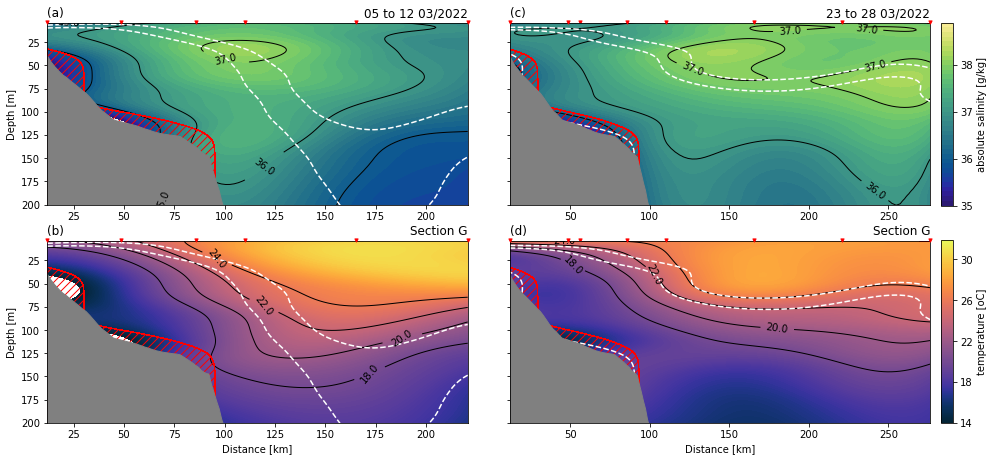

In [91]:
fig,axes = plt.subplots(figsize=[7.91*2, 7.36], nrows=2, ncols=2, sharey=True)

#### PLOTTING SANAGU14 ####
cdicts = dict_with_sections['SANAGU2022_sanagu14_extended_G']

secid = cdicts['secid']
case = cdicts['case']
time_str = cdicts['time']

fig, axes[0,0], _ = subroutine_TSsection(cdicts['sal'], fig=fig, ax=axes[0,0], ax_cbar=axes[0,1], secids=[secid], add_colorbar=False)
fig, axes[1,0], _ = subroutine_TSsection(cdicts['temp'], fig=fig, ax=axes[1,0], ax_cbar=axes[1,1], secids=[secid], add_colorbar=False)

cr = axes[0,0].contour(cdicts['sal']['xm']/1e3, cdicts['sal']['ym'], cdicts['sigmaT']['oa'], 
                       levels=cdicts['sigmaT']['contour'], colors=['white'], linestyles='--', 
                       zorder=1)  # section
cr = axes[1,0].contour(cdicts['sal']['xm']/1e3, cdicts['sal']['ym'], cdicts['sigmaT']['oa'], 
                       levels=cdicts['sigmaT']['contour'], colors=['white'], linestyles='--', 
                       zorder=1)  # section

axes[0,0].set_title('(a)', loc='left')
axes[1,0].set_title('(b)', loc='left')
axes[0,0].set_title(time_str, loc='right')
axes[1,0].set_title(f'Section {secid}', loc='right')
axes[1,0].set_xlabel('Distance [km]')
axes[0,0].set_ylim(ylimdict[secid])
axes[1,0].set_ylim(ylimdict[secid])

axes[0,0].set_xlim(np.nanmin(cdicts['sal']['xm']/1e3), np.nanmax(cdicts['sal']['xm']/1e3))
axes[1,0].set_xlim(np.nanmin(cdicts['sal']['xm']/1e3), np.nanmax(cdicts['sal']['xm']/1e3))

#### PLOTTING SANAGU15 ####
cdicts = dict_with_sections['SANAGU2022_sanagu15_extended_G']

secid = cdicts['secid']
case = cdicts['case']
time_str = cdicts['time']

fig, axes[0,1], cfsalt = subroutine_TSsection(cdicts['sal'], fig=fig, ax=axes[0,1], ax_cbar=axes[0,1], secids=[secid], add_colorbar=False)
fig, axes[1,1], cftemp = subroutine_TSsection(cdicts['temp'], fig=fig, ax=axes[1,1], ax_cbar=axes[1,1], secids=[secid], add_colorbar=False)

cr = axes[0,1].contour(cdicts['sal']['xm']/1e3, cdicts['sal']['ym'], cdicts['sigmaT']['oa'], 
                       levels=cdicts['sigmaT']['contour'], colors=['white'], linestyles='--', 
                       zorder=1)  # section
cr = axes[1,1].contour(cdicts['sal']['xm']/1e3, cdicts['sal']['ym'], cdicts['sigmaT']['oa'], 
                       levels=cdicts['sigmaT']['contour'], colors=['white'], linestyles='--', 
                       zorder=1)  # section

axes[0,1].set_title('(c)', loc='left')
axes[1,1].set_title('(d)', loc='left')
axes[0,1].set_title(time_str, loc='right')
axes[1,1].set_title(f'Section {secid}', loc='right')
axes[1,1].set_xlabel('Distance [km]')
axes[0,1].set_ylim(ylimdict[secid])
axes[1,1].set_ylim(ylimdict[secid])

_ = [ax.set_ylabel('') for ax in [axes[0,1],axes[1,1]]]

#### adding colorbar for each variable
cbaxes = fig.add_axes([0.91, 0.535, 0.01, 0.345])
cbar_salt = plt.colorbar(cfsalt, cax=cbaxes)
cbar_salt.set_label('absolute salinity [g/kg]')

tick_locator = ticker.MaxNLocator(nbins=4)
cbar_salt.locator = tick_locator
cbar_salt.update_ticks()

cbar_salt.ax.set_yticklabels([35, 36, 37, 38])

cbaxes = fig.add_axes([0.91, 0.125, 0.01, 0.345])
cbar_temp = plt.colorbar(cftemp, cax=cbaxes)
cbar_temp.set_label('temperature [oC]')

tick_locator = ticker.MaxNLocator(nbins=5)
cbar_temp.locator = tick_locator
cbar_temp.update_ticks()

cbar_temp.ax.set_yticklabels([14, 18, 22, 26, 30])

fig.patch.set_alpha(1.0)
plt.subplots_adjust(wspace=.1)
plt.savefig('../figures/manuscript/00_manuscript_cruise_transects.png', bbox_inches="tight", dpi=300)

# New Version (after 1st round of revision)

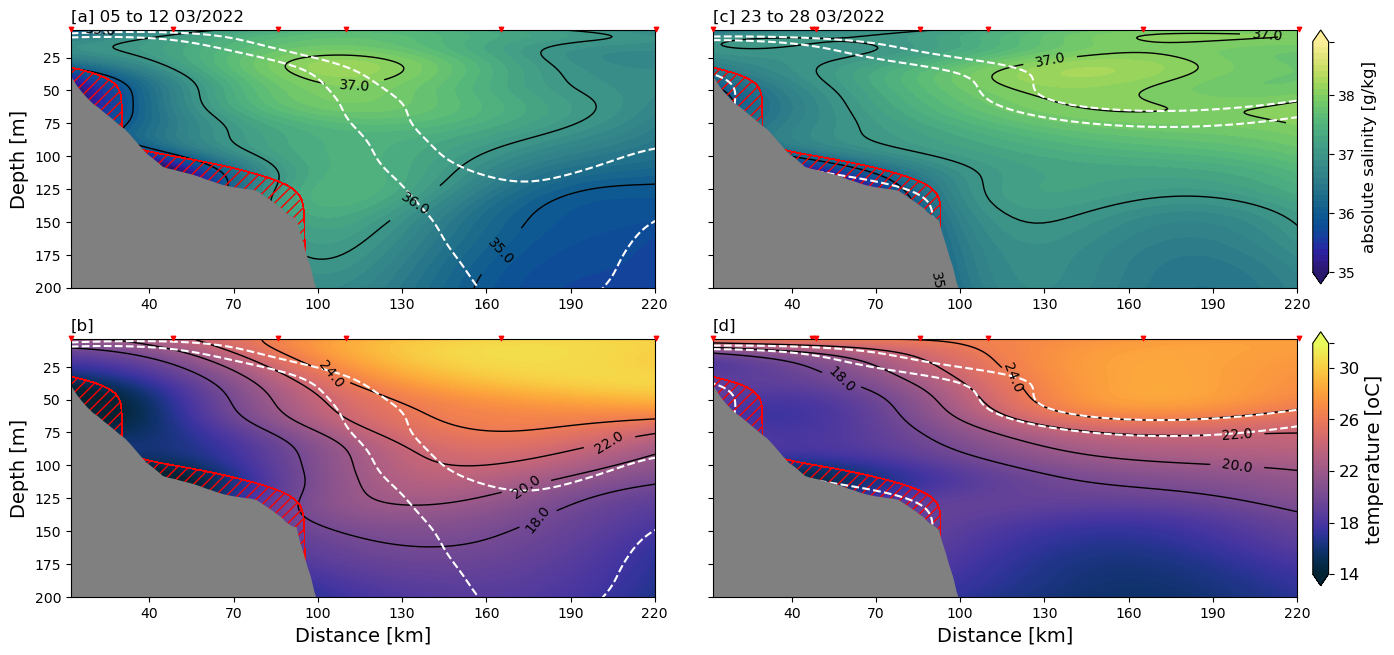

In [29]:
fig,axes = plt.subplots(figsize=[7.91*2, 7.36], nrows=2, ncols=2, sharey=True)

#### PLOTTING SANAGU14 ####
cdicts = dict_with_sections['SANAGU2022_sanagu14_extended_G']

secid = cdicts['secid']
case = cdicts['case']
time_str = cdicts['time']

fig, axes[0,0], _ = subroutine_TSsection(cdicts['sal'], fig=fig, ax=axes[0,0], ax_cbar=axes[0,1], secids=[secid], add_colorbar=False)
fig, axes[1,0], _ = subroutine_TSsection(cdicts['temp'], fig=fig, ax=axes[1,0], ax_cbar=axes[1,1], secids=[secid], add_colorbar=False)

cr = axes[0,0].contour(cdicts['sal']['xm']/1e3, cdicts['sal']['ym'], cdicts['sigmaT']['oa'], 
                       levels=cdicts['sigmaT']['contour'], colors=['white'], linestyles='--', 
                       zorder=1)  # section
cr = axes[1,0].contour(cdicts['sal']['xm']/1e3, cdicts['sal']['ym'], cdicts['sigmaT']['oa'], 
                       levels=cdicts['sigmaT']['contour'], colors=['white'], linestyles='--', 
                       zorder=1)  # section

axes[0,0].set_title(f'[a] {time_str}', loc='left')
axes[1,0].set_title('[b]', loc='left')
# axes[0,0].set_title(time_str, loc='right')
# axes[1,0].set_title(f'Section {secid}', loc='right')
axes[1,0].set_xlabel('Distance [km]', fontsize=14)
axes[0,0].set_ylabel('Depth [m]', fontsize=14)
axes[0,0].set_ylim(ylimdict[secid])
axes[1,0].set_ylim(ylimdict[secid])

axes[0,0].set_xlim(np.nanmin(cdicts['sal']['xm']/1e3), np.nanmax(cdicts['sal']['xm']/1e3))
axes[1,0].set_xlim(np.nanmin(cdicts['sal']['xm']/1e3), np.nanmax(cdicts['sal']['xm']/1e3))

#### PLOTTING SANAGU15 ####
cdicts = dict_with_sections['SANAGU2022_sanagu15_extended_G']

secid = cdicts['secid']
case = cdicts['case']
time_str = cdicts['time']

fig, axes[0,1], cfsalt = subroutine_TSsection(cdicts['sal'], fig=fig, ax=axes[0,1], ax_cbar=axes[0,1], secids=[secid], add_colorbar=False)
fig, axes[1,1], cftemp = subroutine_TSsection(cdicts['temp'], fig=fig, ax=axes[1,1], ax_cbar=axes[1,1], secids=[secid], add_colorbar=False)

cr = axes[0,1].contour(cdicts['sal']['xm']/1e3, cdicts['sal']['ym'], cdicts['sigmaT']['oa'], 
                       levels=cdicts['sigmaT']['contour'], colors=['white'], linestyles='--', 
                       zorder=1)  # section
cr = axes[1,1].contour(cdicts['sal']['xm']/1e3, cdicts['sal']['ym'], cdicts['sigmaT']['oa'], 
                       levels=cdicts['sigmaT']['contour'], colors=['white'], linestyles='--', 
                       zorder=1)  # section

axes[0,1].set_title(f'[c] {time_str}', loc='left')
axes[1,1].set_title('[d]', loc='left')
# axes[0,1].set_title(time_str, loc='right')
# axes[1,1].set_title(f'Section {secid}', loc='right')
axes[1,1].set_xlabel('Distance [km]', fontsize=14)
axes[1,0].set_ylabel('Depth [m]', fontsize=14)
axes[0,1].set_ylim(ylimdict[secid])
axes[1,1].set_ylim(ylimdict[secid])

_ = [ax.set_ylabel('') for ax in [axes[0,1],axes[1,1]]]

#### adding colorbar for each variable
cbaxes = fig.add_axes([0.91, 0.535, 0.01, 0.345])
cbar_salt = plt.colorbar(cfsalt, cax=cbaxes)
cbar_salt.set_label('absolute salinity [g/kg]', fontsize=12)

tick_locator = ticker.MaxNLocator(nbins=4)
cbar_salt.locator = tick_locator
cbar_salt.update_ticks()

cbar_salt.ax.set_yticklabels([35, 36, 37, 38])

cbaxes = fig.add_axes([0.91, 0.125, 0.01, 0.345])
cbar_temp = plt.colorbar(cftemp, cax=cbaxes)
cbar_temp.set_label('temperature [oC]', fontsize=14)

tick_locator = ticker.MaxNLocator(nbins=5)
cbar_temp.locator = tick_locator
cbar_temp.update_ticks()

cbar_temp.ax.set_yticklabels([14, 18, 22, 26, 30], fontsize=12)

fig.patch.set_alpha(1.0)
plt.subplots_adjust(wspace=.1)

# making sure both transect has the same x-axis (ticks and limits) to allow comparison
_ = [ax.set_xticks(np.arange(10,250, 30)) for ax in axes.ravel()]
_ = [ax.set_xlim([12,220]) for ax in axes.ravel()]


# plt.savefig('../figures/manuscript/00_manuscript_cruise_transects.png', bbox_inches="tight", dpi=300)

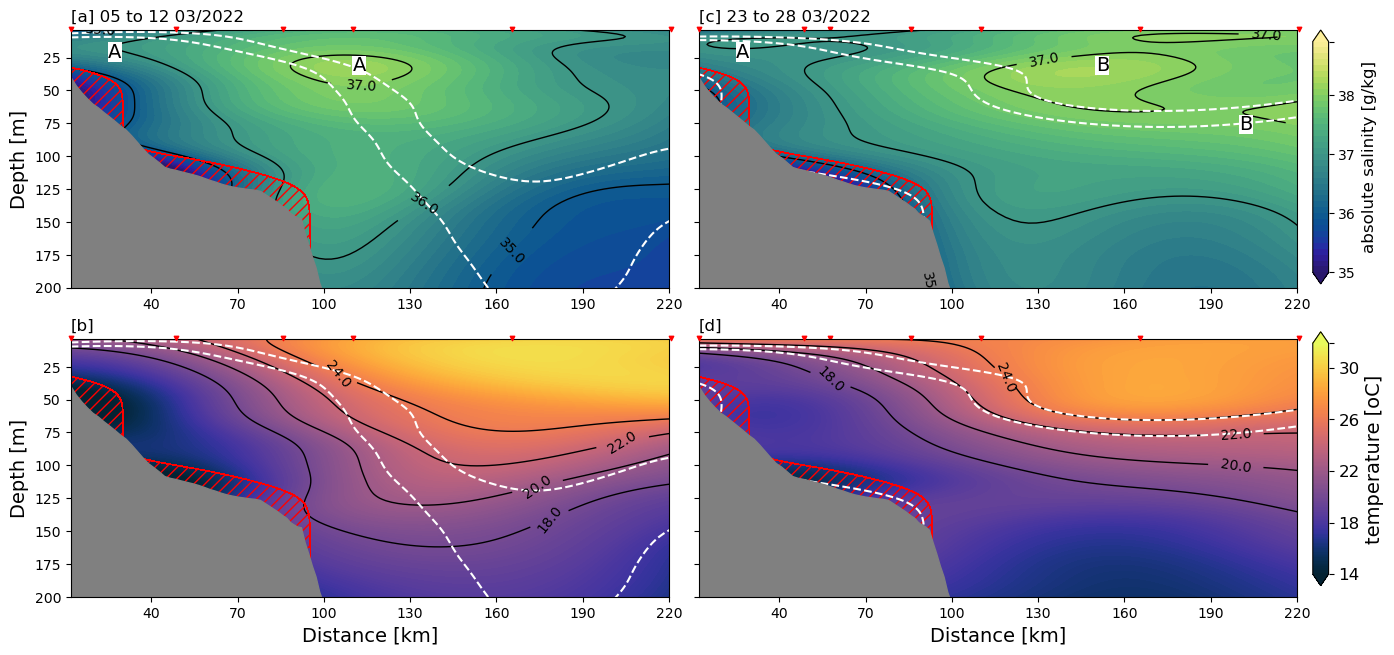

In [8]:
fig,axes = plt.subplots(figsize=[7.91*2, 7.36], nrows=2, ncols=2, sharey=True)

#### PLOTTING SANAGU14 ####
cdicts = dict_with_sections['SANAGU2022_sanagu14_extended_G']

secid = cdicts['secid']
case = cdicts['case']
time_str = cdicts['time']

fig, axes[0,0], _ = subroutine_TSsection(cdicts['sal'], fig=fig, ax=axes[0,0], ax_cbar=axes[0,1], secids=[secid], add_colorbar=False)
fig, axes[1,0], _ = subroutine_TSsection(cdicts['temp'], fig=fig, ax=axes[1,0], ax_cbar=axes[1,1], secids=[secid], add_colorbar=False)

cr = axes[0,0].contour(cdicts['sal']['xm']/1e3, cdicts['sal']['ym'], cdicts['sigmaT']['oa'], 
                       levels=cdicts['sigmaT']['contour'], colors=['white'], linestyles='--', 
                       zorder=1)  # section
cr = axes[1,0].contour(cdicts['sal']['xm']/1e3, cdicts['sal']['ym'], cdicts['sigmaT']['oa'], 
                       levels=cdicts['sigmaT']['contour'], colors=['white'], linestyles='--', 
                       zorder=1)  # section

axes[0,0].set_title(f'[a] {time_str}', loc='left')
axes[1,0].set_title('[b]', loc='left')
# axes[0,0].set_title(time_str, loc='right')
# axes[1,0].set_title(f'Section {secid}', loc='right')
axes[1,0].set_xlabel('Distance [km]', fontsize=14)
axes[0,0].set_ylabel('Depth [m]', fontsize=14)
axes[0,0].set_ylim(ylimdict[secid])
axes[1,0].set_ylim(ylimdict[secid])

axes[0,0].set_xlim(np.nanmin(cdicts['sal']['xm']/1e3), np.nanmax(cdicts['sal']['xm']/1e3))
axes[1,0].set_xlim(np.nanmin(cdicts['sal']['xm']/1e3), np.nanmax(cdicts['sal']['xm']/1e3))

#### PLOTTING SANAGU15 ####
cdicts = dict_with_sections['SANAGU2022_sanagu15_extended_G']

secid = cdicts['secid']
case = cdicts['case']
time_str = cdicts['time']

fig, axes[0,1], cfsalt = subroutine_TSsection(cdicts['sal'], fig=fig, ax=axes[0,1], ax_cbar=axes[0,1], secids=[secid], add_colorbar=False)
fig, axes[1,1], cftemp = subroutine_TSsection(cdicts['temp'], fig=fig, ax=axes[1,1], ax_cbar=axes[1,1], secids=[secid], add_colorbar=False)

cr = axes[0,1].contour(cdicts['sal']['xm']/1e3, cdicts['sal']['ym'], cdicts['sigmaT']['oa'], 
                       levels=cdicts['sigmaT']['contour'], colors=['white'], linestyles='--', 
                       zorder=1)  # section
cr = axes[1,1].contour(cdicts['sal']['xm']/1e3, cdicts['sal']['ym'], cdicts['sigmaT']['oa'], 
                       levels=cdicts['sigmaT']['contour'], colors=['white'], linestyles='--', 
                       zorder=1)  # section

axes[0,1].set_title(f'[c] {time_str}', loc='left')
axes[1,1].set_title('[d]', loc='left')
# axes[0,1].set_title(time_str, loc='right')
# axes[1,1].set_title(f'Section {secid}', loc='right')
axes[1,1].set_xlabel('Distance [km]', fontsize=14)
axes[1,0].set_ylabel('Depth [m]', fontsize=14)
axes[0,1].set_ylim(ylimdict[secid])
axes[1,1].set_ylim(ylimdict[secid])

_ = [ax.set_ylabel('') for ax in [axes[0,1],axes[1,1]]]

#### adding colorbar for each variable
cbaxes = fig.add_axes([0.91, 0.535, 0.01, 0.345])
cbar_salt = plt.colorbar(cfsalt, cax=cbaxes)
cbar_salt.set_label('absolute salinity [g/kg]', fontsize=12)

tick_locator = ticker.MaxNLocator(nbins=4)
cbar_salt.locator = tick_locator
cbar_salt.update_ticks()

cbar_salt.ax.set_yticklabels([35, 36, 37, 38])

cbaxes = fig.add_axes([0.91, 0.125, 0.01, 0.345])
cbar_temp = plt.colorbar(cftemp, cax=cbaxes)
cbar_temp.set_label('temperature [oC]', fontsize=14)

tick_locator = ticker.MaxNLocator(nbins=5)
cbar_temp.locator = tick_locator
cbar_temp.update_ticks()

cbar_temp.ax.set_yticklabels([14, 18, 22, 26, 30], fontsize=12)

fig.patch.set_alpha(1.0)
plt.subplots_adjust(wspace=.05)

# making sure both transect has the same x-axis (ticks and limits) to allow comparison
_ = [ax.set_xticks(np.arange(10,250, 30)) for ax in axes.ravel()]
_ = [ax.set_xlim([12,220]) for ax in axes.ravel()]

ax = axes.ravel()[0]
ax.text(25, 25, 'A', ha='left', bbox=dict(facecolor='white', edgecolor='none', pad=0.1), fontsize=14)
ax.text(110, 35, 'A', ha='left', bbox=dict(facecolor='white', edgecolor='none', pad=0.1), fontsize=14)

ax = axes.ravel()[1]
ax.text(25, 25, 'A', ha='left', bbox=dict(facecolor='white', edgecolor='none', pad=0.1), fontsize=14)
ax.text(150, 35, 'B', ha='left', bbox=dict(facecolor='white', edgecolor='none', pad=0.1), fontsize=14)
ax.text(200, 80, 'B', ha='left', bbox=dict(facecolor='white', edgecolor='none', pad=0.1), fontsize=14)


plt.savefig('../figures/manuscript/00_manuscript_cruise_transects.png', bbox_inches="tight", dpi=300)